# Étape 14 : peut-on croire les probabilités ? Calibration et explications

Le modèle retenu (étape 13) est la régression logistique sur les 11 variables à 15 min.
Jusqu'ici on l'a jugé sur la **log loss**. Deux questions restent avant de l'afficher
à un joueur dans l'appli :

1. **Calibration** : quand le modèle annonce 70 %, le bleu gagne-t-il vraiment environ
   70 % du temps ? Un modèle peut bien classer les parties (bonne AUC) et pourtant annoncer
   des pourcentages faux, par exemple trop sûrs d'eux.
2. **Explications** : pour UNE partie, pourquoi 70 % ? Quelles variables ont poussé vers
   le bleu, lesquelles vers le rouge ? On utilise les **valeurs de SHAP** : la prédiction
   est découpée en une base (la partie « moyenne ») plus une contribution par variable.

On compare toujours avec LightGBM : les arbres boostés sont connus pour être moins bien
calibrés que la logistique, c'est l'occasion de le vérifier.

Plan :
1. Connexion, données, modèles
2. La courbe de fiabilité
3. Faut-il recalibrer ?
4. Explications globales : quelles variables comptent le plus ?
5. Explications locales : trois parties décortiquées
6. Conclusions

## 1. Connexion, données, modèles

Avant de lancer : Docker Desktop ouvert et `docker compose start` fait.

Nouveau module `src/explain.py` : les outils de calibration et les valeurs de SHAP.
**Pas besoin du paquet `shap`** : pour une logistique, la contribution d'une variable est
simplement coefficient × (valeur − moyenne) ; pour LightGBM, la bibliothèque calcule elle-même
les valeurs de SHAP (`pred_contrib=True`). Un paquet lourd en moins, et on sait d'où viennent
les chiffres.

Mêmes données et même découpage qu'aux étapes 13 et 13 bis : le test (les 20 % de parties
les plus récentes, ~950) n'a servi qu'une fois, pour le choix final du modèle. On le réutilise ici pour
**décrire** ce modèle, pas pour en choisir un autre.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from explain import (calibration_fit, expected_calibration_error, explain_game,
                     fit_recalibrator, linear_contributions, oof_predictions,
                     reliability_table, tree_contributions)
from features import FEATURES, ROLE_FEATURES, TARGET, build_features, time_split
from models import evaluate, fit_predict, make_lgbm, make_logit, paired_bootstrap

warnings.filterwarnings("ignore", message="X does not have valid feature names")
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})

df = build_features()
train, test = time_split(df, test_frac=0.2)
y_test = test[TARGET].to_numpy()

BEST_LGBM = {"num_leaves": 4, "n_estimators": 200}
LGBM_COLS = FEATURES + ROLE_FEATURES
models = {
    "Logit": (make_logit, FEATURES),
    "LightGBM": (lambda: make_lgbm(**BEST_LGBM), LGBM_COLS),
}
pred, fitted = {}, {}
for name, (make, cols) in models.items():
    pred[name], fitted[name] = fit_predict(make, cols, train, test)

print(f"{len(train)} parties d'entraînement, {len(test)} de test.")
print(f"Victoires du bleu : {train[TARGET].mean():.1%} à l'entraînement, {y_test.mean():.1%} au test.")
for name, p in pred.items():
    print(f"{name:9s} : log loss {evaluate(y_test, p)['log_loss']:.4f}, "
          f"probabilité moyenne annoncée {p.mean():.1%}")

3809 parties d'entraînement, 953 de test.
Victoires du bleu : 48.8% à l'entraînement, 47.1% au test.
Logit     : log loss 0.5242, probabilité moyenne annoncée 46.8%
LightGBM  : log loss 0.5284, probabilité moyenne annoncée 47.1%


## 2. La courbe de fiabilité

**Le principe.** On range les ~950 parties du test par probabilité annoncée, en 10 groupes de
~95 parties (déciles). Pour chaque groupe on compare la probabilité **annoncée** (moyenne) et le
taux de victoire **réel**. Sur un modèle bien calibré, les points tombent sur la diagonale.
Les barres verticales sont les intervalles de confiance à 95 % du taux réel : avec ~95 parties
par groupe, ils font environ ±10 points, donc un point un peu à côté de la diagonale n'est pas
forcément un défaut.

**Trois chiffres pour résumer :**
- **Brier** : erreur quadratique moyenne des probabilités (plus bas = mieux, 0,25 = pile ou face).
- **ECE** (*expected calibration error*) : écart moyen entre annoncé et réel sur les déciles.
- **Pente et ordonnée de calibration** : on refait une petite régression logistique du résultat sur
  la prédiction du modèle (en log-odds). Pente 1 et ordonnée 0 = parfait. Une pente < 1 veut dire
  que le modèle est **trop sûr de lui** (> 1 : trop timide) ; une ordonnée ≠ 0 qu'il surestime ou
  sous-estime le bleu en général. Avec leur **intervalle de confiance** : si l'IC de la pente contient 1
  et celui de l'ordonnée contient 0, on ne peut pas dire que le modèle est mal calibré.

In [2]:
tables = {name: reliability_table(y_test, p) for name, p in pred.items()}
summary = pd.DataFrame({
    name: {"brier": evaluate(y_test, p)["brier"], "ECE": expected_calibration_error(y_test, p),
           **calibration_fit(y_test, p),
           "déciles dans l'IC": f"{int(tables[name]['dans_ic'].sum())} / 10"}
    for name, p in pred.items()
}).T
summary

,brier,ECE,pente,pente IC,ordonnée,ordonnée IC,déciles dans l'IC
Logit,0.175217,0.027641,1.038284,0.89 à 1.18,0.021264,-0.13 à 0.17,10 / 10
LightGBM,0.17724,0.041912,1.060965,0.91 à 1.21,0.010414,-0.14 à 0.16,9 / 10


In [3]:
tables["Logit"].round(3)

,parties,annoncé,réel,ic_bas,ic_haut,dans_ic
groupe,,,,,,
1,96,0.068,0.062,0.029,0.130,True
2,95,0.157,0.221,0.149,0.314,True
3,95,0.239,0.242,0.167,0.337,True
4,95,0.326,0.316,0.231,0.415,True
5,96,0.407,0.312,0.229,0.411,True
6,95,0.502,0.495,0.396,0.594,True
7,95,0.594,0.589,0.489,0.683,True
8,95,0.689,0.716,0.618,0.797,True
9,95,0.792,0.811,0.720,0.877,True


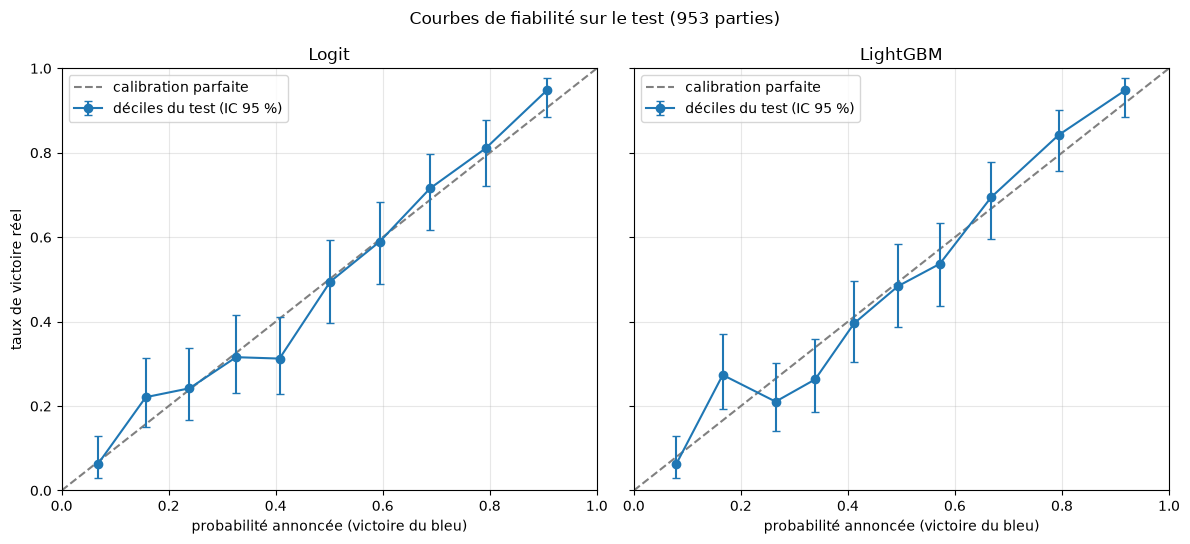

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
for ax, (name, t) in zip(axes, tables.items()):
    ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="calibration parfaite")
    ax.errorbar(t["annoncé"], t["réel"],
                yerr=[t["réel"] - t["ic_bas"], t["ic_haut"] - t["réel"]],
                marker="o", capsize=3, linestyle="-", label="déciles du test (IC 95 %)")
    ax.set(title=name, xlabel="probabilité annoncée (victoire du bleu)", xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="upper left")
axes[0].set_ylabel("taux de victoire réel")
plt.suptitle(f"Courbes de fiabilité sur le test ({len(test)} parties)")
plt.tight_layout()
plt.show()

**La distribution des probabilités** compte aussi : un modèle qui annonce toujours 50 % est
parfaitement calibré mais inutile. On veut des probabilités **bien calibrées ET étalées**.

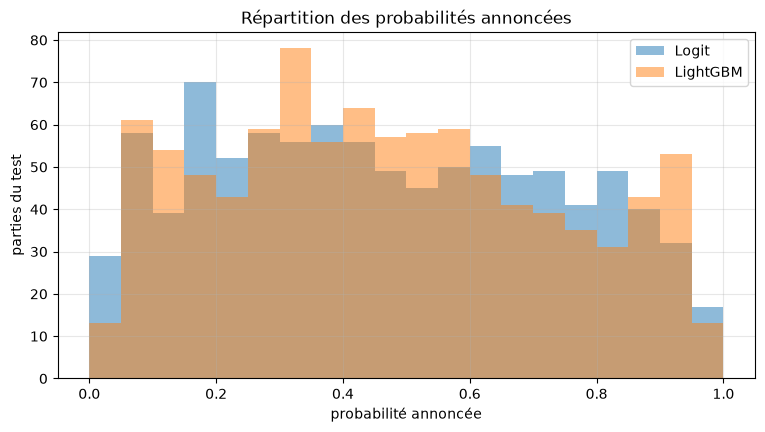

Logit     : 35% des parties annoncées à moins de 20 % ou plus de 80 %
LightGBM  : 33% des parties annoncées à moins de 20 % ou plus de 80 %


In [5]:
fig, ax = plt.subplots()
for name, p in pred.items():
    ax.hist(p, bins=20, range=(0, 1), alpha=0.5, label=name)
ax.set(xlabel="probabilité annoncée", ylabel="parties du test",
       title="Répartition des probabilités annoncées")
ax.legend()
plt.show()
for name, p in pred.items():
    sure = ((p < 0.2) | (p > 0.8)).mean()
    print(f"{name:9s} : {sure:.0%} des parties annoncées à moins de 20 % ou plus de 80 %")

## 3. Faut-il recalibrer ?

Si les probabilités sont décalées, on peut les **corriger après coup** avec une petite fonction
apprise sur des prédictions que le modèle a faites sur des parties qu'il n'avait pas vues :
- **Platt** : une mini régression logistique sur la probabilité (2 paramètres : corrige la pente
  et l'ordonnée) ;
- **isotonique** : une fonction en escalier croissante, plus souple mais qui demande plus de données.

**Sans fuite** : la correction est apprise sur les prédictions « hors pli » de l'entraînement
(`oof_predictions` : chaque partie est prédite par un modèle entraîné sans elle, avec les plis
chronologiques de l'étape 13), jamais sur le test.

**Un piège** : les prédictions hors pli viennent de modèles entraînés sur MOINS de parties que le
modèle final (le pli 1 n'en a que ~640, contre ~3 800 pour le modèle final). Un modèle entraîné sur
peu de parties est plus « sûr de lui » à tort. Une correction apprise sur ces prédictions peut donc
corriger un défaut… que le modèle final n'a pas. La ligne « hors pli » du premier tableau montre
la calibration de ces prédictions : à comparer avec celle du test.

**Règle fixée avant de regarder** : on garde un recalibrage seulement s'il améliore la log loss
du test **et** que l'intervalle du bootstrap apparié exclut 0. Sinon, une correction ajoute
de la complexité pour rien. (Le test sert ici à **vérifier** une correction apprise ailleurs, pas
à en choisir une parmi beaucoup : avec 2 candidates, le risque de « choisir la chance » est faible.)

In [6]:
oof = {name: oof_predictions(make, cols, train) for name, (make, cols) in models.items()}
pd.DataFrame({
    **{f"{name}, hors pli (entraînement)": calibration_fit(o["y"], o["p"]) for name, o in oof.items()},
    **{f"{name}, test": calibration_fit(y_test, p) for name, p in pred.items()},
}).T

,pente,pente IC,ordonnée,ordonnée IC
"Logit, hors pli (entraînement)",0.925934,0.86 à 1.00,-0.006833,-0.09 à 0.08
"LightGBM, hors pli (entraînement)",0.931404,0.86 à 1.00,-0.032941,-0.12 à 0.05
"Logit, test",1.038284,0.89 à 1.18,0.021264,-0.13 à 0.17
"LightGBM, test",1.060965,0.91 à 1.21,0.010414,-0.14 à 0.16


In [7]:
recal_rows = []
recal_pred = {}
for name, (make, cols) in models.items():
    for method in ["platt", "isotonic"]:
        fix = fit_recalibrator(oof[name]["y"], oof[name]["p"], method)
        p_fix = fix(pred[name])
        recal_pred[(name, method)] = p_fix
        diff, low, high = paired_bootstrap(y_test, pred[name], p_fix)
        recal_rows.append({"modèle": name, "recalibrage": method,
                           "log loss avant": evaluate(y_test, pred[name])["log_loss"],
                           "log loss après": evaluate(y_test, p_fix)["log_loss"],
                           "écart": diff, "IC bas": low, "IC haut": high,
                           "ECE après": expected_calibration_error(y_test, p_fix),
                           "à garder": bool(high < 0)})
recal = pd.DataFrame(recal_rows).set_index(["modèle", "recalibrage"])
recal.round(4)

log loss avant  log loss après   écart  IC bas  IC haut  ECE après  à garder
modèle   recalibrage                                                                              
Logit    platt                0.5242          0.5253  0.0011 -0.0011   0.0032     0.0340     False
         isotonic             0.5242          0.5307  0.0065 -0.0024   0.0180     0.0459     False
LightGBM platt                0.5284          0.5297  0.0013 -0.0007   0.0032     0.0461     False
         isotonic             0.5284          0.5351  0.0067  0.0011   0.0127     0.0680     False

## 4. Explications globales : quelles variables comptent le plus ?

**Valeurs de SHAP en une phrase** : pour une partie, la prédiction (en log-odds, l'échelle
« avant la courbe en S ») = une **base** (la prédiction pour une partie moyenne) + une
**contribution** par variable. Une contribution positive pousse vers le bleu, négative vers le rouge.

Pour l'importance **globale** d'une variable, on fait la moyenne de la **valeur absolue** de ses
contributions sur toutes les parties du test : « de combien, en moyenne, cette variable déplace
la prédiction ». On vérifie d'abord que base + contributions redonne bien la probabilité du modèle.

In [8]:
X_logit = test[FEATURES]
X_lgbm = test[LGBM_COLS]
contrib_logit, base_logit = linear_contributions(fitted["Logit"], X_logit)
contrib_lgbm, base_lgbm = tree_contributions(fitted["LightGBM"], X_lgbm)

check_logit = np.abs(expit(base_logit + contrib_logit.sum(axis=1)) - pred["Logit"]).max()
check_lgbm = np.abs(expit(base_lgbm + contrib_lgbm.sum(axis=1)) - pred["LightGBM"]).max()
print(f"Vérification (écart max avec predict_proba) : Logit {check_logit:.1e}, LightGBM {check_lgbm:.1e}")
print(f"Base (partie moyenne) : Logit {expit(base_logit):.1%}, LightGBM {expit(base_lgbm):.1%}")

importance = pd.DataFrame({
    "Logit": contrib_logit.abs().mean(),
    "LightGBM": contrib_lgbm.abs().mean(),
}).sort_values("Logit", ascending=False)
importance.round(3)

Vérification (écart max avec predict_proba) : Logit 2.2e-16, LightGBM 4.4e-16
Base (partie moyenne) : Logit 48.3%, LightGBM 49.0%


,Logit,LightGBM
gold_k,0.822,0.548
dragons_diff,0.411,0.210
xp_k,0.278,0.252
first_dragon,0.157,0.000
grubs_diff,0.098,0.049
cs_diff,0.074,0.015
plates_diff,0.069,0.086
kills_diff,0.066,0.098
towers_diff,0.051,0.000
first_blood,0.021,0.000


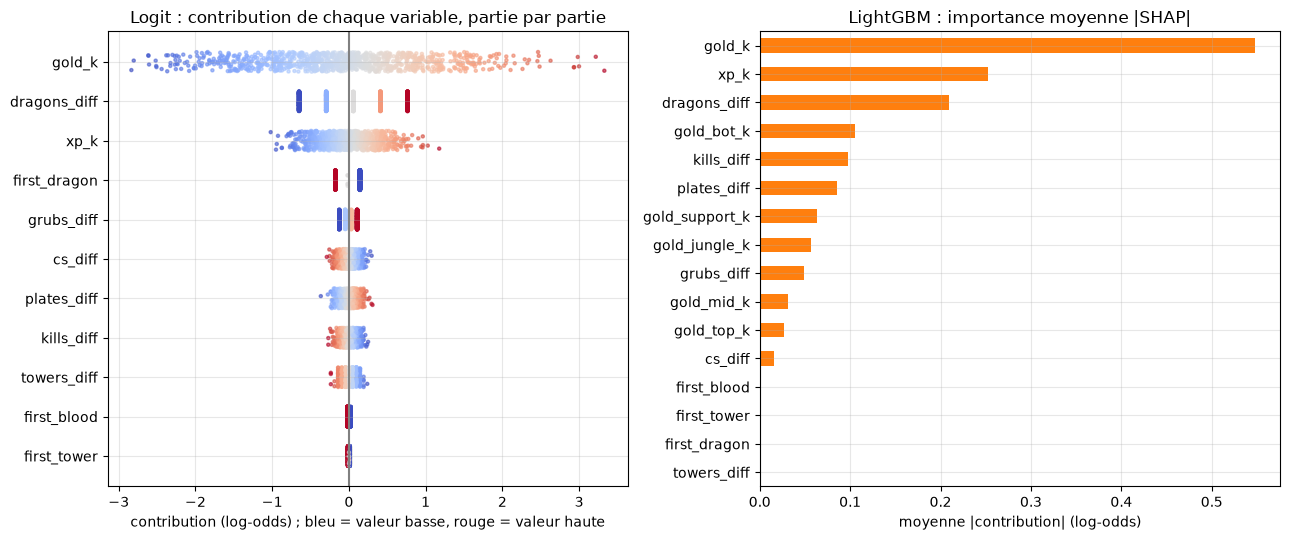

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
order = contrib_logit.abs().mean().sort_values().index
rng = np.random.default_rng(0)
for i, col in enumerate(order):
    values = X_logit[col]
    colors = (values - values.min()) / (values.max() - values.min() + 1e-9)
    axes[0].scatter(contrib_logit[col], i + rng.uniform(-0.25, 0.25, len(values)),
                    c=colors, cmap="coolwarm", s=5, alpha=0.6)
axes[0].set_yticks(range(len(order)), order)
axes[0].axvline(0, color="grey")
axes[0].set(title="Logit : contribution de chaque variable, partie par partie",
            xlabel="contribution (log-odds) ; bleu = valeur basse, rouge = valeur haute")

contrib_lgbm.abs().mean().sort_values().plot.barh(ax=axes[1], color="tab:orange")
axes[1].set(title="LightGBM : importance moyenne |SHAP|", xlabel="moyenne |contribution| (log-odds)")
plt.tight_layout()
plt.show()

**Comment lire le nuage de gauche.** Chaque point est une partie. Pour `gold_k`, les points rouges
(gros écart d'or en faveur du bleu) sont à droite (poussent vers le bleu), les bleus à gauche :
c'est la relation attendue. Une variable dont les points restent collés à 0 ne change presque
jamais la prédiction. Pour la logistique, chaque ligne est une droite (contribution proportionnelle
à la valeur) : c'est ce qui la rend si facile à expliquer.

**Deux limites à connaître** (questions classiques en entretien) :
- **Variables corrélées** : l'or et l'XP bougent ensemble (corrélation ~0,9). SHAP partage l'effet
  entre elles selon les coefficients du modèle ; une autre logistique tout aussi bonne pourrait
  partager autrement. On lit donc « or + XP » comme un bloc, pas chaque variable séparément.
- **Expliquer le modèle ≠ expliquer le jeu** : SHAP dit pourquoi le *modèle* annonce 70 %,
  pas qu'un dragon *cause* la victoire (même limite que les coefficients de l'étape 11).
- **LightGBM répartit l'or entre l'or total et l'or par poste** : ses importances par variable ne
  se comparent pas une à une avec celles de la logistique ; on compare plutôt les grands blocs.

## 5. Explications locales : trois parties décortiquées

On prend trois parties du test :
- **la plus sûre et juste** : le modèle annonçait un résultat très probable, et il est arrivé ;
- **la plus grosse surprise** : le modèle était très sûr, et l'autre équipe a gagné ;
- **la plus serrée** : le modèle annonçait environ 50 %.

Pour chacune : la base (partie moyenne), les 6 variables qui ont le plus pesé, et la probabilité
après chaque étape. Les identifiants des parties sont tronqués (on n'affiche pas les joueurs).


=== la plus sûre et juste : partie EUW1_8027…, annoncé 99% pour le bleu, gagnant : bleu ===
Base (partie moyenne) : 48%
                  contribution (log-odds)  probabilité après  valeur dans la partie
gold_k                              3.329              0.963                 12.429
dragons_diff                        0.764              0.982                  2.000
xp_k                                0.679              0.991                  6.728
plates_diff                         0.295              0.993                 23.000
towers_diff                        -0.235              0.992                  5.000
kills_diff                         -0.186              0.990                 16.000
autres variables                   -0.269              0.987                    NaN

=== la plus grosse surprise : partie EUW1_8028…, annoncé 96% pour le bleu, gagnant : rouge ===
Base (partie moyenne) : 48%
                  contribution (log-odds)  probabilité après  valeur dans la partie

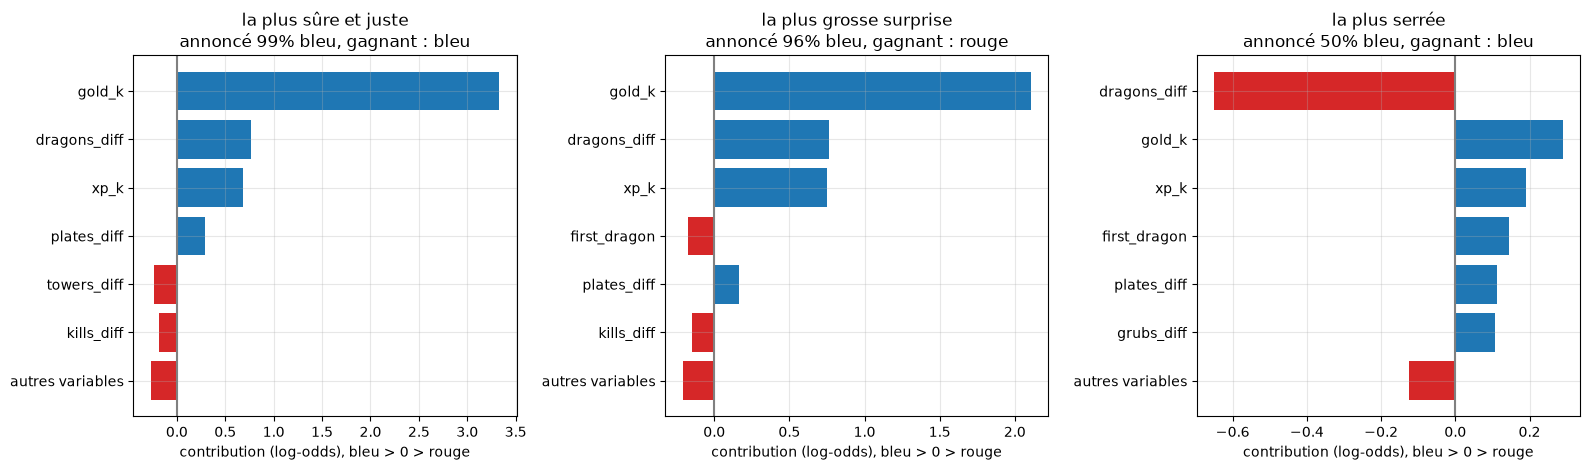

In [10]:
p = pred["Logit"]
confidence = np.abs(p - 0.5)
correct = (p >= 0.5) == (y_test == 1)
picks = {
    "la plus sûre et juste": int(np.argmax(np.where(correct, confidence, -1))),
    "la plus grosse surprise": int(np.argmax(np.where(~correct, confidence, -1))),
    "la plus serrée": int(np.argmin(confidence)),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (label, i) in zip(axes, picks.items()):
    row = contrib_logit.iloc[i]
    table, start, end = explain_game(row, base_logit)
    winner = "bleu" if y_test[i] == 1 else "rouge"
    print(f"\n=== {label} : partie {test['match_id'].iloc[i][:9]}…, "
          f"annoncé {end:.0%} pour le bleu, gagnant : {winner} ===")
    print(f"Base (partie moyenne) : {start:.0%}")
    shown = table.copy()
    shown["valeur dans la partie"] = [X_logit.iloc[i][c] if c in X_logit.columns else np.nan
                                      for c in shown.index]
    print(shown.round(3).to_string())

    steps = table["contribution (log-odds)"]
    ax.barh(range(len(steps))[::-1], steps.values,
            color=["tab:blue" if v > 0 else "tab:red" for v in steps.values])
    ax.set_yticks(range(len(steps))[::-1], steps.index)
    ax.axvline(0, color="grey")
    ax.set(title=f"{label}\nannoncé {end:.0%} bleu, gagnant : {winner}",
           xlabel="contribution (log-odds), bleu > 0 > rouge")
plt.tight_layout()
plt.show()

## 6. Conclusions

*(Exécuté le 2 nov. 2026 sur la vraie base : 3 809 parties d'entraînement, 953 de test.)*

**1. Les probabilités de la logistique sont bien calibrées, telles quelles.**
- Test : Brier 0,175, ECE 2,8 points, pente de calibration 1,04 (IC 0,89 à 1,18), ordonnée 0,02 (IC −0,13 à 0,17).
  Les deux IC contiennent la valeur parfaite (1 et 0), et les 10 déciles ont un taux réel compatible avec la probabilité annoncée.
- Le seul décile un peu à côté est le 5e (annoncé 41 %, réel 31 %) ; son IC (23 % à 41 %) touche encore l'annonce : c'est du bruit
  normal avec ~95 parties par groupe (sur 10 groupes, on s'attend à en voir un qui s'écarte).
- Les probabilités sont aussi **étalées** : 35 % des parties sont annoncées à moins de 20 % ou plus de 80 %. Le modèle n'est pas
  « calibré parce que prudent ».

**2. LightGBM est un peu moins bien calibré** (ECE 4,2 points, 9 déciles sur 10 dans l'IC, Brier 0,177), conforme à sa réputation,
mais l'écart reste petit : ses probabilités suivent aussi la diagonale (pente 1,06).

**3. Aucun recalibrage n'est gardé** (règle fixée avant : meilleur au test ET IC qui exclut 0).
- Platt : +0,001 de log loss pour la logistique (IC −0,001 à +0,003), donc rien ; isotonique : +0,007, plus mauvais.
- Le piège annoncé se voit : les prédictions hors pli ont une pente de 0,93 (IC 0,86 à 1,00), un peu « trop sûres d'elles »,
  parce qu'elles viennent de modèles entraînés sur 640 à 3 200 parties. Le modèle final (3 809 parties) n'a pas ce défaut
  (pente 1,04 au test). Une correction apprise sur ces prédictions « corrigerait » un défaut qui n'existe pas.
- L'isotonique fait pire que Platt : une fonction en escalier apprise sur ~3 000 parties suit le bruit.

**4. Ce qui pèse dans les prédictions (SHAP, moyenne des |contributions| en log-odds, logistique) :**
écart d'or 0,82, loin devant ; écart de dragons 0,41 ; XP 0,28 ; premier dragon 0,16 ; le reste moins de 0,10.
LightGBM donne le même ordre (or, XP, dragons ; son or est en plus réparti entre l'or total et l'or par poste, surtout le bot).
Les premiers sang / première tour ne pèsent presque rien une fois l'or connu : leur effet passe déjà par l'or.

**5. Des signes « bizarres » qui n'en sont pas.** Pour les kills, les tours et les CS, une valeur haute pousse un peu vers le
**rouge** (points rouges à gauche dans le nuage). Ce sont des effets **à or égal** : l'or compte déjà les kills, les tours et les CS,
donc le modèle ne garde que ce qui reste une fois l'or connu, et ce reste est petit (contributions de ±0,3 au plus) et difficile à
interpréter. Même chose pour le premier dragon à nombre de dragons égal. SHAP d'une logistique hérite de ses coefficients :
il explique le **modèle**, pas une cause dans le jeu.

**6. Les parties décortiquées montrent les limites à 15 min.** La plus grosse surprise : bleu annoncé à 96 % (+7 900 d'or,
+2 dragons, +7 400 XP), le rouge a gagné. Ces retournements sont attendus et la calibration les compte déjà (le décile le
plus haut, annoncé 91 %, a perdu 5 % du temps), mais aucune variable à 15 min ne peut dire lesquels arriveront.

**Décision :** on garde la régression logistique de l'étape 13 **sans recalibrage**. Pour l'appli, on pourra afficher sa
probabilité telle quelle, et l'explication par `linear_contributions` + `explain_game` (base, puis les variables qui
ont le plus pesé). Suite du plan : le README en anglais avec les résultats et les figures.